In [1]:
import os
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms

from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset, random_split

In [ ]:
ruta_dataset = r"hand-sign-images"

In [16]:
transformaciones = transforms.Compose([
    transforms.Resize((56, 56)),
    transforms.ColorJitter(brightness=0.2, contrast=0.15),
    transforms.ToTensor()
])

In [ ]:
dataset_train_completo = ImageFolder(
    root=os.path.join(ruta_dataset, "Train"),
    transform=transformaciones
)

dataset_test_completo = ImageFolder(
    root=os.path.join(ruta_dataset, "Test"),
    transform=transformaciones
)


In [ ]:
categorias = list("ABCDEFGHIK")

assert dataset_train_completo.classes[:10] == categorias, \
    "Las primeras categorías no coinciden"

assert dataset_train_completo.classes == dataset_test_completo.classes, \
    "Las categorías de Train y Test no coinciden"



In [ ]:
indices_train = [
    i for i, (_, etiqueta) in enumerate(dataset_train_completo.samples)
    if etiqueta < 10
]

indices_test = [
    i for i, (_, etiqueta) in enumerate(dataset_test_completo.samples)
    if etiqueta < 10
]


dataset_entrenamiento_completo = Subset(
    dataset_train_completo, indices_train
)

dataset_test = Subset(
    dataset_test_completo, indices_test
)


In [ ]:
n_entrenamiento = int(0.85 * len(dataset_entrenamiento_completo))
n_validacion = len(dataset_entrenamiento_completo) - n_entrenamiento

dataset_entrenamiento, dataset_validacion = random_split(
    dataset_entrenamiento_completo,
    [n_entrenamiento, n_validacion],
    generator=torch.Generator().manual_seed(42)
)

In [17]:
dataloader_entrenamiento = DataLoader(
    dataset_entrenamiento,
    batch_size=64,
    shuffle=True
)

dataloader_validacion = DataLoader(
    dataset_validacion,
    batch_size=64,
    shuffle=False
)

dataloader_test = DataLoader(
    dataset_test,
    batch_size=64,
    shuffle=False
)

In [ ]:
print("Categorías:", categorias)
print("Imágenes de entrenamiento:", len(dataset_entrenamiento))
print("Imágenes de validación:", len(dataset_validacion))
print("Imágenes de test:", len(dataset_test))


Categorías: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K']
Imágenes de entrenamiento: 9363
Imágenes de validación: 1653
Imágenes de test: 3466


In [ ]:
imagenes, etiquetas = next(iter(dataloader_entrenamiento))

print("Dimensiones del batch:", imagenes.shape)
print("Dimensiones de las etiquetas:", etiquetas.shape)


Dimensiones del batch: torch.Size([32, 3, 56, 56])
Dimensiones de las etiquetas: torch.Size([32])


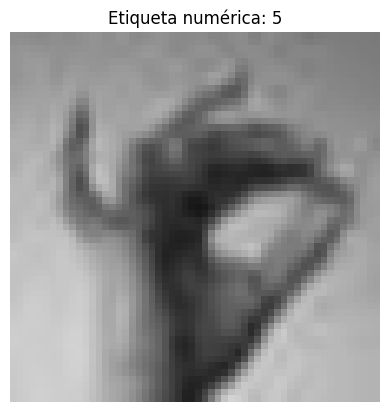

In [ ]:
imagen = imagenes[0].permute(1, 2, 0).numpy()

plt.axis("off")
plt.title(f"Etiqueta numérica: {etiquetas[0].item()}")
plt.imshow(imagen)
plt.show()

In [18]:
class ConvNet(nn.Module):
    def __init__(self):
        super(ConvNet, self).__init__()

        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=16,
            kernel_size=5,
            stride=1,
            padding=2
        )

        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=5,
            stride=1,
            padding=2
        )

        self.conv3 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=5,
            stride=1,
            padding=2
        )

        self.pool1 = nn.MaxPool2d(
            kernel_size=2,
            stride=2,
            padding=0
        )

        self.dropout1 = nn.Dropout(p=0.25)

        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))

        x = self.pool1(F.relu(self.conv2(x)))

        x = self.pool1(F.relu(self.conv3(x)))

        x = x.view(-1, 64 * 7 * 7)

        x = F.relu(self.fc1(x))
        x = self.dropout1(x)
        x = self.fc2(x)

        return x


modelo_prueba = ConvNet()

salidas = modelo_prueba(imagenes)

print("Dimensiones de entrada:", imagenes.shape)
print("Dimensiones de salida de la CNN:", salidas.shape)



import copy
import torch.optim as optim

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'*** Utilizando {device}')

modelo = ConvNet().to(device)
criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters(), lr=0.001)

print('*** Modelo cargado')

epocas = 50  
paciencia = 3  

valores_perdida_train = []
valores_perdida_validacion = []
exactitud_entrenamiento = []
exactitud_validacion = []

mejor_perdida_val = float('inf')  
mejor_epoca = 0                  
mejor_estado = None              
epocas_sin_mejora = 0             

print('*** Comienza entrenamiento')

for epoca in range(epocas):

    modelo.train()

    train_loss = 0.0
    aciertos_train = 0
    total_train = 0

    for images, labels in dataloader_entrenamiento:

        images, labels = images.to(device), labels.to(device)

        optimizador.zero_grad()

        outputs = modelo(images)
        loss = criterio(outputs, labels)

        loss.backward()
        optimizador.step()

        train_loss += loss.item() * labels.size(0)

        predicciones = outputs.argmax(dim=1)
        aciertos_train += (predicciones == labels).sum().item()
        total_train += labels.size(0)

    perdida_train = train_loss / total_train
    accuracy_train = aciertos_train / total_train

    valores_perdida_train.append(perdida_train)
    exactitud_entrenamiento.append(accuracy_train)

    modelo.eval()

    val_loss = 0.0
    aciertos_val = 0
    total_val = 0

    with torch.no_grad():

        for images, labels in dataloader_validacion:

            images, labels = images.to(device), labels.to(device)

            outputs = modelo(images)
            loss = criterio(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predicciones = outputs.argmax(dim=1)
            aciertos_val += (predicciones == labels).sum().item()
            total_val += labels.size(0)

    perdida_val = val_loss / total_val
    accuracy_val = aciertos_val / total_val

    valores_perdida_validacion.append(perdida_val)
    exactitud_validacion.append(accuracy_val)

    print(
        f'Época {epoca + 1:2d}/{epocas} | '
        f'Train loss: {perdida_train:.4f} | '
        f'Val loss: {perdida_val:.4f} | '
        f'Train accuracy: {accuracy_train:.4f} | '
        f'Val accuracy: {accuracy_val:.4f}'
    )

    if perdida_val < mejor_perdida_val:
        mejor_perdida_val = perdida_val
        mejor_epoca = epoca + 1
        mejor_estado = copy.deepcopy(modelo.state_dict())
        epocas_sin_mejora = 0
        print("   -> Mejora en validación: guardamos este modelo")
    else:
        epocas_sin_mejora += 1
        print(f"   -> Sin mejora ({epocas_sin_mejora}/{paciencia})")

        if epocas_sin_mejora >= paciencia:
            print(f"\nParada temprana en la época {epoca+1}: "
                  f"la mejor fue la {mejor_epoca} (Val Loss: {mejor_perdida_val:.4f})")
            break

print('*** Entrenamiento finalizado')

modelo.load_state_dict(mejor_estado)
print(f'\nModelo restaurado a la época {mejor_epoca} (Val Loss: {mejor_perdida_val:.4f})')

torch.save(mejor_estado, 'mejor_modelo_cnn.pt')



Dimensiones de entrada: torch.Size([32, 3, 56, 56])
Dimensiones de salida de la CNN: torch.Size([32, 10])
*** Utilizando cpu
*** Modelo cargado
*** Comienza entrenamiento
Época  1/50 | Train loss: 1.1058 | Val loss: 0.1805 | Train accuracy: 0.5974 | Val accuracy: 0.9359
   -> Mejora en validación: guardamos este modelo
Época  2/50 | Train loss: 0.1220 | Val loss: 0.0188 | Train accuracy: 0.9608 | Val accuracy: 0.9964
   -> Mejora en validación: guardamos este modelo
Época  3/50 | Train loss: 0.0402 | Val loss: 0.0068 | Train accuracy: 0.9871 | Val accuracy: 0.9994
   -> Mejora en validación: guardamos este modelo
Época  4/50 | Train loss: 0.0310 | Val loss: 0.0009 | Train accuracy: 0.9900 | Val accuracy: 1.0000
   -> Mejora en validación: guardamos este modelo
Época  5/50 | Train loss: 0.0187 | Val loss: 0.0012 | Train accuracy: 0.9935 | Val accuracy: 1.0000
   -> Sin mejora (1/3)
Época  6/50 | Train loss: 0.0199 | Val loss: 0.0006 | Train accuracy: 0.9935 | Val accuracy: 1.0000
   -> 

In [19]:

modelo.eval()

aciertos_test = 0
total_test = 0
perdida_test_total = 0.0

predicciones_test = []
etiquetas_reales_test = []

with torch.no_grad():
    for images, labels in dataloader_test:
        images = images.to(device)
        labels = labels.to(device)

        outputs = modelo(images)
        loss = criterio(outputs, labels)

        predicciones = outputs.argmax(dim=1)

        perdida_test_total += loss.item() * labels.size(0)
        aciertos_test += (predicciones == labels).sum().item()
        total_test += labels.size(0)

        predicciones_test.extend(predicciones.cpu().numpy())
        etiquetas_reales_test.extend(labels.cpu().numpy())

perdida_test = perdida_test_total / total_test
accuracy_test = aciertos_test / total_test

print("\n*** RESULTADOS FINALES EN TEST ***")
print(f"Pérdida de test: {perdida_test:.4f}")
print(f"Precisión de test: {accuracy_test * 100:.2f}%")
print(f"Imágenes clasificadas correctamente: {aciertos_test} de {total_test}")



*** RESULTADOS FINALES EN TEST ***
Pérdida de test: 0.1054
Precisión de test: 97.72%
Imágenes clasificadas correctamente: 3387 de 3466


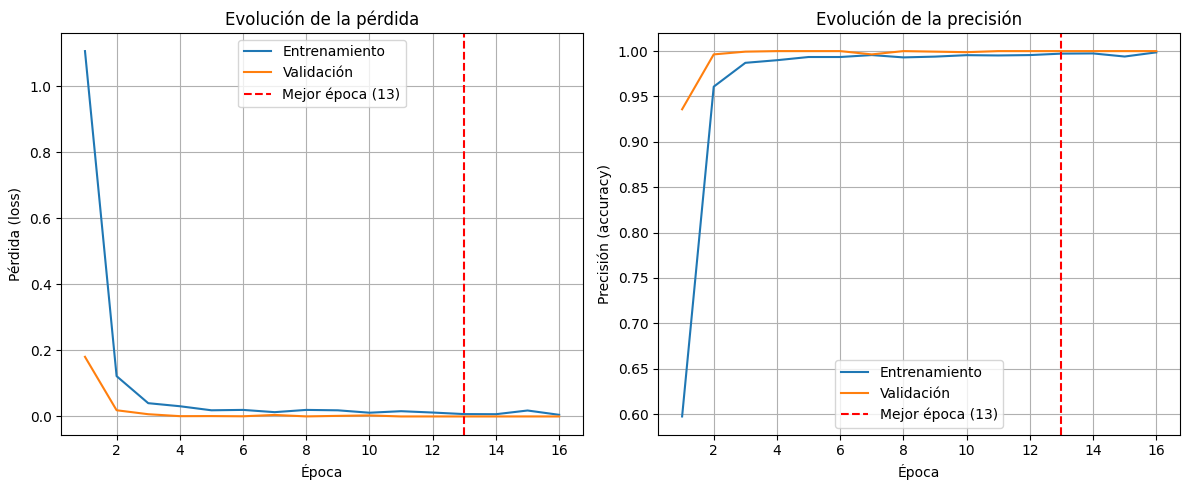

In [20]:
epocas_grafica = range(1, len(valores_perdida_train) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epocas_grafica, valores_perdida_train, label="Entrenamiento")
plt.plot(epocas_grafica, valores_perdida_validacion, label="Validación")
plt.axvline(mejor_epoca, color="red", linestyle="--", label=f"Mejor época ({mejor_epoca})") # Línea de parada temprana
plt.xlabel("Época")
plt.ylabel("Pérdida (loss)")
plt.title("Evolución de la pérdida")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epocas_grafica, exactitud_entrenamiento, label="Entrenamiento")
plt.plot(epocas_grafica, exactitud_validacion, label="Validación")
plt.axvline(mejor_epoca, color="red", linestyle="--", label=f"Mejor época ({mejor_epoca})") # Línea de parada temprana
plt.xlabel("Época")
plt.ylabel("Precisión (accuracy)")
plt.title("Evolución de la precisión")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

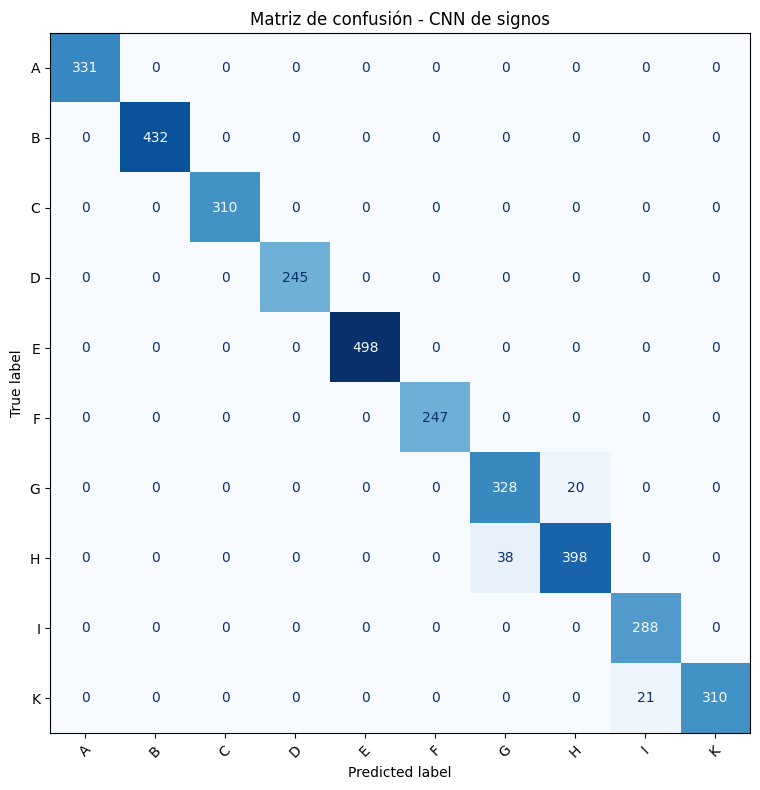

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz = confusion_matrix(
    etiquetas_reales_test,
    predicciones_test,
    labels=list(range(len(categorias)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=categorias
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Matriz de confusión - CNN de signos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
